# The Knight's Maze

### Lab 3 · The hidden maze

<img src="https://unitoraicourse.vercel.app/art/knight-maze-preview.png" alt="The knight lights the hidden maze with his torch while the dragon waits in the dark" width="100%">

A knight (K) is tasked to retrieve the treasure (G) hidden in the dungeon without being caught by a dragon (D). 

The knight is suddently thrown in the dark. He cannot see anymore the right path. Equipped with a torch, he is bravely facing only the few visible cells in front of him. 

The Maze has also grown more treacherous, - the goblins have spat *Oil* on some cells, which cannot be walked on deterministically anymore. 

You can work on this page, on Google Colab, or locally (see *Running the code*). In any case, upload a notebook back on the platform once you are finished. 



### AI Policy: 

While AI can be used, I do not recommended using it for directly writing the code to solve the exercises. [Preliminary research](https://arxiv.org/abs/2506.08872) shows reduced EEG connectivity when offloading to AI, inducing poorer retention. 

I recommend to try solving the exercise without AI, and interrogate AI on how to understand specific portions of the code, or how to use specific functions in python, rather than actually writing the code. 

The goal always not to solve the exercise, but to learn. When you will start working, you will probably be using mostly AI for writing code, - but if you can't understand the code that AI is writing, it will be impossible to debug or to understand the implication of what you are doing. 

***We ask you to disclose at the start of the notebook the kind of AI assistance that was used to solve the exercises.***

## The exercise

The dungeon is a grid of cells. In the initial version, the knight starts top-left, the treasure is bottom-right and the dragon starts in the middle. The base version is a 10*10 connected graph, with no walls. Additional versions have walls, like in this example: 

    █████████████████
    █ K .   █   .   █
    █   ·   █   ·   █
    █   .   █ D .   █
    █   █████   ·   █
    █   .   .   . G █
    █████████████████

**Rules.** Each turn the knight moves first, then the dragon. A move is a step (in the four directions, no diagonal moves) to a neighbouring cell with no wall in between, or staying still. The knight wins when it reaches the treasure. It loses if it ends up on the same cell as the dragon, or if 200 turns pass without reaching the treasure. 

---

<span style="color:teal"><b>Thinking budget.</b></span> . The thinking_budget refers to the amount of times *neighbours* is called inside the knight class. 

<span style="color:teal">**Oil.**</span> Some floors are oily. A move off an oily cell may skid: with probability `slip` (0.4 unless the level says otherwise) the knight ends up one step to the left or to the right of where it meant to go, or stays where it is if a wall is in the way. Standing still on oil is safe, and the dragon never slips. You can tell an oily cell with `state.maze.is_oil(cell)`.

<span style="color:teal">**The hidden dungeon.**</span> In the hidden levels the dungeon is dark and the knight sees only the cells within `sight` steps of it, walls blocking the view. Those cells are in `state.visible`, and `state.maze.neighbours()`, `is_open()` and `is_oil()` answer only for them: asking about any other cell loses the game. `state.dragon` is the dragon only while it is in view (else `None`), and there is no `state.history`. Whatever the knight wants to remember, it has to store itself, in `reset()` and `next_move()`. These levels are about *online search*: the knight learns the maze while it moves. Greedy local search gets stuck in dead ends; online DFS, LRTA\* or a map built step by step get out of them.


### The Notebook.

The notebook has a lot of code to draw the maze and to evaluate the runs. You don't have to read them and can simply run those. 

You should first familiarise with the maze, and be able to make the knight navigate it statically, by computing both BFS and Dijkstra on the static maze. 

Once you are able to draw paths across the maze, you can add those strategies to the knight. 


**Levels.** 

| Level | Dragon | Algorithm | To pass |
|---|---|---|---|
| 1 | `StaticDragon`: sleeps where it stands | BFS, with the dragon's cell treated as a wall | ≥ 95 % of 50 random mazes |
| 2 | `GuardDragon`: sleeps, but hunts you if you come within 3 steps of its lair | Dijkstra, with a cost that grows near the dragon | ≥ 75 % of 50 random mazes |
| 2.5 | `GreedyDragon` | your choice | 90 |
| 3 | `ChaserDragon` at half or full speed, on mazes with loops (`"density": 0.5`) | your choice | 70 |
| 4 | `StaticDragon` in a 20×20 dungeon (`density: 0.5`), treasure on the right edge, **thinking budget 280** | A\* with an admissible heuristic: BFS needs more than 300 lookups here | ≥ 95 % of 50 mazes |
| 5 | `StaticDragon` in an open 20×20 hall (`density: 0.3`), **thinking budget 120** | A\* alone is not enough: break ties well, or use a stronger heuristic | ≥ 95 % of 50 mazes |
| 6 | `PatrolDragon`: walks between its lair and the treasure, never standing on it; its rounds are in `state.dragon_at(k)`, **thinking budget 280** | A\* every turn with the dragon as a wall; or plan in time with the dragon's rounds | ≥ 90 % of 50 mazes |
| 9 | **Lantern**: the dungeon is dark, the knight sees 2 steps around it; `StaticDragon`, 300 turns | online search: greedy gets stuck in dead ends; online DFS, LRTA\* or a map built step by step get out of them | ≥ 90 % of 50 mazes |
| 10 | **Dark and slippery**: as 9, with ten oily cells (`slip` 0.4) | a skid puts you off your plan: plan again from where you are | ≥ 90 % of 50 mazes |
| 11 | **Guard in the dark**: loops (`density: 0.5`), the knight sees 3 steps, `GuardDragon` at half speed hunts within 3 steps of its lair | remember where you saw the dragon and keep away from there | ≥ 80 % of 50 mazes |


**Testing** The last cell allows you to both have a visual experience of the maze, or to run evaluate on 50 mazes.


In [ ]:
"""The maze: a rows x cols grid graph, drawn as text.

Each cell (row, col) is a node, and two neighbouring cells are connected
unless there is a wall between them. A new maze has no walls. You can add
them through the `walls` parameter, with add_wall(), or with random_walls().

    maze = Maze(4, 6, walls=[((0, 0), (0, 1)), ((1, 2), (2, 2))])
    print(maze)

Walls are drawn as solid blocks, and cells are separated by faint dots so
the grid stays visible even with no walls. Paths are drawn as arrows
pointing to the next cell: single arrows for the knight, double arrows
for the dragon, and a cross where both passed.

Notebooks show a maze at the end of a cell as a picture instead, and
maze.draw() makes a picture with marks and paths (see the next cell).

Inside a `with maze.thinking(budget)` block the maze also counts the cells
whose neighbours you ask for: that is the knight's thinking budget. See
Maze.thinking() and the search cell below.

A hidden maze (hidden=True) is in the dark: the knight only sees the cells
within `sight` steps of where it stands, and walls block the view. Tell the
maze where the knight is with look_from(cell). From then on neighbours(),
maze[cell] and is_open() answer only for visible cells and raise Unseen for
any other, and adjacency() always raises Unseen: there is no map to copy,
the knight has to build its own. maze.visible holds the cells in view now
and maze.seen the cells seen so far; pictures draw the rest as fog. See
Maze.look_from() and the hidden maze cell below.

Some cells may be oily (`oil`, add_oil(), pour_oil(), is_oil()): a move off
an oily cell may skid sideways. The rule is in the game cell; the maze only
remembers where the oil is and draws it as a puddle (a ~ in text).
"""
import random
from contextlib import contextmanager

DIRECTIONS = ((-1, 0), (1, 0), (0, -1), (0, 1))  # up, down, left, right

WALL, DOT, BOTH, FOG = "█", "·", "✕", "░"
ARROWS = {
    "knight": {(-1, 0): "↑", (1, 0): "↓", (0, -1): "←", (0, 1): "→"},
    "dragon": {(-1, 0): "⇑", (1, 0): "⇓", (0, -1): "⇐", (0, 1): "⇒"},
}


def manhattan(a, b):
    """Grid distance between two cells, ignoring walls."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def path_arrows(path, arrows):
    """{cell: arrow pointing to the next cell on the path}. A cell visited
    more than once keeps its latest arrow; the last cell gets none."""
    out = {}
    for a, b in zip(path, path[1:]):
        if a != b:
            out[tuple(a)] = arrows[(b[0] - a[0], b[1] - a[1])]
    return out


class OutOfThought(Exception):
    """A search looked at more cells than its thinking budget allows."""


class Unseen(Exception):
    """A hidden maze was asked about a cell the knight cannot see."""


class Maze:
    def __init__(self, rows=10, cols=None, walls=(), hidden=False, sight=2, oil=()):
        """A rows x cols maze (square if cols is omitted).

        `walls` is a list of pairs of neighbouring cells with a wall between
        them, e.g. [((0, 0), (0, 1))] puts a wall between the two top-left
        cells. `oil` is a list of oily cells, see add_oil().

        With hidden=True the maze is in the dark: only the cells within
        `sight` steps of the knight can be looked at, see look_from().
        """
        self.rows = rows
        self.cols = rows if cols is None else cols
        self.walls = set()
        for a, b in walls:
            self.add_wall(a, b)
        self.looked, self._budget, self._counting = [], None, False   # see thinking()
        self.hidden, self.sight = hidden, sight                        # see look_from()
        self.viewer, self.visible, self.seen = None, frozenset(), set()
        self.oil = set()                                               # see add_oil()
        for cell in oil:
            self.add_oil(cell)

    # ---------- cells and walls ----------

    def in_bounds(self, cell):
        r, c = cell
        return 0 <= r < self.rows and 0 <= c < self.cols

    def cells(self):
        """All cells, row by row."""
        return [(r, c) for r in range(self.rows) for c in range(self.cols)]

    def _edge(self, a, b):
        a, b = tuple(a), tuple(b)
        if not (self.in_bounds(a) and self.in_bounds(b)) or manhattan(a, b) != 1:
            raise ValueError(
                f"a wall must separate two neighbouring cells inside the "
                f"{self.rows}x{self.cols} maze, got {a} and {b}")
        return frozenset((a, b))

    def add_wall(self, a, b):
        self.walls.add(self._edge(a, b))

    # ---------- oil ----------

    def add_oil(self, cell):
        """Pour oil on a cell: a move off it may skid, see the game cell."""
        cell = tuple(cell)
        if not self.in_bounds(cell):
            raise ValueError(f"{cell} is outside the {self.rows}x{self.cols} maze")
        self.oil.add(cell)

    def is_oil(self, cell):
        """True if the cell is oily. Free; in a hidden maze the cell must be
        visible (see look_from), as for neighbours()."""
        self._look(cell)
        return tuple(cell) in self.oil

    def pour_oil(self, count=4, size=1, seed=None, avoid=()):
        """Pour `count` random puddles of size x size cells, with no wall
        inside a puddle and none of the cells in `avoid` (say the start and
        the goal) under oil. Returns the oily cells added. Fewer puddles are
        poured if the maze has no room for them."""
        rng, avoid, added = random.Random(seed), {tuple(c) for c in avoid}, []
        for _ in range(100 * count):
            if len(added) >= count * size * size:
                break
            r, c = rng.randrange(self.rows - size + 1), rng.randrange(self.cols - size + 1)
            puddle = [(r + i, c + j) for i in range(size) for j in range(size)]
            if any(cell in avoid or cell in self.oil for cell in puddle):
                continue
            if any(not self._open(a, b) for a in puddle for b in puddle if manhattan(a, b) == 1):
                continue
            for cell in puddle:
                self.add_oil(cell)
            added += puddle
        return added

    def _open(self, a, b):
        """True if you can step directly from cell a to cell b. Free: used by
        the drawing code and by neighbours()."""
        return (self.in_bounds(a) and self.in_bounds(b) and manhattan(a, b) == 1
                and frozenset((a, b)) not in self.walls)

    def is_open(self, a, b):
        """True if you can step directly from cell a to cell b. Costs one unit
        of thinking, see thinking(); in a hidden maze, a must be visible."""
        self._look(a)
        self._charge(a)
        return self._open(a, b)

    # ---------- graph view ----------

    def neighbours(self, cell):
        """Cells you can step to from `cell` (up, down, left, right). Costs
        one unit of thinking, see thinking(). In a hidden maze `cell` must
        be visible, or Unseen is raised: see look_from()."""
        self._look(cell)
        self._charge(cell)
        r, c = cell
        return [(r + dr, c + dc) for dr, dc in DIRECTIONS
                if self._open(cell, (r + dr, c + dc))]

    __getitem__ = neighbours        # maze[cell] is the same as maze.neighbours(cell)

    def adjacency(self):
        """The whole maze as an adjacency list: {cell: [neighbours]}. Not
        available in a hidden maze: there is no map to copy."""
        if self.hidden:
            raise Unseen("the maze is hidden: there is no adjacency list to copy, "
                         "look around with neighbours() from where the knight stands")
        return {cell: self.neighbours(cell) for cell in self.cells()}

    # ---------- sight: hidden mazes ----------

    def visible_from(self, cell):
        """The cells within `sight` steps of `cell`, walls blocking the view:
        the cell itself, its open neighbours, their open neighbours, and so on
        `sight` times. Free, and the same whether the maze is hidden or not."""
        cell = tuple(cell)
        lit, ring = {cell}, {cell}
        for _ in range(self.sight):
            ring = {(r + dr, c + dc) for r, c in ring for dr, dc in DIRECTIONS
                    if self._open((r, c), (r + dr, c + dc))} - lit
            lit |= ring
        return frozenset(lit)

    def look_from(self, cell):
        """Put the knight on `cell`: from now on the visible cells are those
        within `sight` steps of it (see visible_from), and they are added to
        `seen`. Returns the visible cells. Call it after every move of the
        knight when exploring a hidden maze. Free."""
        if not self.in_bounds(cell):
            raise ValueError(f"{tuple(cell)} is outside the {self.rows}x{self.cols} maze")
        self.viewer = tuple(cell)
        self.visible = self.visible_from(self.viewer)
        self.seen |= self.visible
        return self.visible

    def known(self, a, b):
        """Whether the knight knows about the wall (or passage) between the
        neighbouring cells a and b: always, unless the maze is hidden and
        neither cell has been seen. Free; used by the drawing code."""
        return not self.hidden or tuple(a) in self.seen or tuple(b) in self.seen

    def _look(self, cell):
        """Raise Unseen if the maze is hidden and `cell` is not in view."""
        if self.hidden and tuple(cell) not in self.visible:
            where = (f"from {self.viewer}" if self.viewer is not None
                     else "before look_from() told the maze where the knight stands")
            raise Unseen(f"cannot look at {tuple(cell)}: it is not visible {where}")

    @contextmanager
    def _revealed(self):
        """Lift the fog inside the block. The game uses it for the dragon's
        turn and for its own checks: the dragon knows the dungeon."""
        hidden, self.hidden = self.hidden, False
        try:
            yield self
        finally:
            self.hidden = hidden

    def _shown(self, cell, mark):
        """Whether a mark is drawn on a hidden maze: the knight always, the
        dragon only while in view, anything else once its cell has been seen."""
        if not self.hidden or mark in ("K", "X"):
            return True
        return cell in self.visible or (mark != "D" and cell in self.seen)

    # ---------- thinking ----------

    @contextmanager
    def thinking(self, budget=None):
        """Count the cells looked at inside the block, and stop at `budget`.

            with maze.thinking(budget=50):
                path = bfs(maze, start, goal)
            maze.expanded      how many cells the search looked at
            maze.looked        those cells, in order (to draw them)

        One unit of thinking = one request for the neighbours of a cell:
        maze.neighbours(cell), maze[cell], state.moves_from(cell) and
        maze.is_open(a, b) cost 1 each; maze.adjacency() costs one per cell;
        asking twice for the same cell costs twice. Everything else is free,
        and outside the block nothing is counted. When the budget runs out
        the next request raises OutOfThought. Blocks nest: one opened inside
        another keeps the outer count and budget, so a search that opens its
        own block cannot escape the budget it is run under.
        """
        if self._counting:
            yield self
            return
        self.looked, self._budget, self._counting = [], budget, True
        try:
            yield self
        finally:
            self._counting = False

    @property
    def expanded(self):
        """How many cells the last thinking() block looked at."""
        return len(self.looked)

    def _charge(self, cell):
        if self._counting:
            if self._budget is not None and len(self.looked) >= self._budget:
                raise OutOfThought(f"looked at {len(self.looked)} cells, the budget is "
                                   f"{self._budget}; could not look at {tuple(cell)}")
            self.looked.append(tuple(cell))

    # ---------- drawing ----------

    def _wall_above(self, r, c):
        """Wall on the top edge of cell (r, c); r == rows is the bottom border.
        In a hidden maze a wall the knight has not seen is drawn as open."""
        return r in (0, self.rows) or (self.known((r - 1, c), (r, c))
                                       and not self._open((r - 1, c), (r, c)))

    def _wall_left(self, r, c):
        """Wall on the left edge of cell (r, c); c == cols is the right border."""
        return c in (0, self.cols) or (self.known((r, c - 1), (r, c))
                                       and not self._open((r, c - 1), (r, c)))

    def _wall_at_corner(self, r, c):
        """True if any wall segment touches the corner point (r, c)."""
        return ((c < self.cols and self._wall_above(r, c))
                or (c > 0 and self._wall_above(r, c - 1))
                or (r < self.rows and self._wall_left(r, c))
                or (r > 0 and self._wall_left(r - 1, c)))

    def render(self, marks=None, knight_path=(), dragon_path=()):
        """The maze as text.

        `marks` maps cells to single characters, e.g. {(0, 0): "K"}, and is
        drawn on top of the paths; `knight_path` and `dragon_path` are
        lists of cells, drawn as arrows; oily cells show a ~ under them.
        In a hidden maze the cells the knight has not seen are drawn as
        fog, with no walls and no marks.
        """
        km = path_arrows(list(knight_path), ARROWS["knight"])
        dm = path_arrows(list(dragon_path), ARROWS["dragon"])
        symbols = {cell: BOTH if cell in km and cell in dm else km.get(cell) or dm[cell]
                   for cell in set(km) | set(dm)}
        for cell in self.oil:
            symbols.setdefault(cell, "~")
        symbols.update({tuple(cell): ch for cell, ch in (marks or {}).items()
                        if self._shown(tuple(cell), ch)})

        lines = []
        for r in range(self.rows + 1):
            line = ""
            for c in range(self.cols + 1):
                line += WALL if self._wall_at_corner(r, c) else DOT
                if c < self.cols:
                    line += WALL * 3 if self._wall_above(r, c) else "   "
            lines.append(line)
            if r < self.rows:
                line = ""
                for c in range(self.cols + 1):
                    line += WALL if self._wall_left(r, c) else " "
                    if c < self.cols:
                        if self.hidden and (r, c) not in self.seen:
                            line += FOG * 3
                        else:
                            line += " " + symbols.get((r, c), " ") + " "
                lines.append(line)
        return "\n".join(lines)

    def __str__(self):
        return self.render()

    __repr__ = __str__  # shown where pictures can't be

    def draw(self, marks=None, knight_path=(), dragon_path=(), caption=""):
        """The drawing of render() as a picture: notebooks show it as an image
        (at the end of a cell, or with display()), print() as text."""
        text = self.render(marks, knight_path, dragon_path)
        return Drawing(maze_svg(self, marks, knight_path, dragon_path, caption),
                       text + "\n" + caption if caption else text)

    def _repr_svg_(self):
        """The picture notebooks show when a maze ends a cell."""
        return maze_svg(self)


def random_walls(rows, cols=None, density=0.8, seed=None):
    """Walls for a random maze in which every cell can be reached.

    It first builds a "perfect" maze, with exactly one path between any two
    cells, by randomised depth-first search, then keeps each of its walls
    with probability `density`. density=1 gives the perfect maze, which has
    no loops, so a dragon can always corner the knight in a dead end; lower
    values knock walls down and open up loops; density=0 gives no walls.
    """
    cols = rows if cols is None else cols
    rng = random.Random(seed)
    seen, stack, passages = {(0, 0)}, [(0, 0)], set()
    while stack:
        r, c = stack[-1]
        options = [(r + dr, c + dc) for dr, dc in DIRECTIONS
                   if 0 <= r + dr < rows and 0 <= c + dc < cols
                   and (r + dr, c + dc) not in seen]
        if options:
            nxt = rng.choice(options)
            seen.add(nxt)
            stack.append(nxt)
            passages.add(frozenset(((r, c), nxt)))
        else:
            stack.pop()

    walls = []
    for r in range(rows):
        for c in range(cols):
            for nb in ((r, c + 1), (r + 1, c)):
                if nb[0] < rows and nb[1] < cols:
                    if frozenset(((r, c), nb)) not in passages and rng.random() < density:
                        walls.append(((r, c), nb))
    return walls

In [ ]:
"""Pictures of the maze: the board drawn as an SVG image, with sprites for
the knight, the dragon and the treasure.

In Jupyter, Colab and the course portal, a maze or a game at the end of a
cell is shown as a picture, and play() animates it; print() still gives
the text drawing. maze.draw() takes the same arguments as maze.render():

    maze.draw({(0, 0): "K", (9, 9): "G"}, knight_path=path)

The marks K, D and G are drawn as the knight, the dragon and the treasure,
and X as the knight caught by the dragon; any other mark as a character.
STYLE picks the look: "token", "pixel", "line" or "dungeon". The dungeon
shows the maze from above and a little from the south, its walls standing
up as blocks of stone, in the dark of a hidden maze lit by the torch.

A hidden maze (see Maze.look_from) is drawn from the knight's point of
view, and the knight carries a torch: cells he has never seen are fog,
with no walls and no marks; cells seen before are dim; the cells in view
glow. The treasure stays on the picture once seen, the dragon shows only
while it is in view. Oily cells are drawn as pixel-art puddles of oil
with a rainbow sheen, one lumpy puddle per patch of oily cells with no
wall between them (in a hidden maze, once seen).
"""
from html import escape
import base64
import math
import random
import struct
import zlib

STYLE = "dungeon" ## token, dungeon, pixel, line
CELL, PAD, LINE_HEIGHT = 40, 12, 18   # pixels: a maze cell, the margin, a caption line
FONT = 'font-family="ui-monospace, Menlo, Consolas, monospace"'
CHAR_WIDTH = 7.2                      # pixels per caption character in that font


def _pixels(art, palette):
    """SVG rectangles for pixel art: one string per row, one character per
    pixel, "." for none. A run of one colour in a row is one rectangle."""
    rects = []
    for y, row in enumerate(art):
        x = 0
        while x < len(row):
            end = x
            while end < len(row) and row[end] == row[x]:
                end += 1
            if row[x] != ".":
                rects.append(f'<rect x="{x}" y="{y}" width="{end - x}" height="1" fill="{palette[row[x]]}"/>')
            x = end
    return "".join(rects)


def _mirror(halves):
    """Rows of symmetric pixel art, from their left halves."""
    return [half + half[::-1] for half in halves]


def _token(face, rim, emblem):
    """A round game token with an emblem, in a 100 x 100 box."""
    return ('<ellipse cx="50" cy="93" rx="32" ry="5" fill="#000" fill-opacity=".35"/>'
            f'<circle cx="50" cy="49" r="44" fill="{rim}"/><circle cx="50" cy="46" r="42" fill="{face}"/>'
            '<path d="M19 33a38 38 0 0 1 62 0" fill="none" stroke="#fff" stroke-opacity=".25" '
            'stroke-width="4" stroke-linecap="round"/>' + emblem)


def _line(ink, paper, body):
    """A line icon in a 100 x 100 box, filled with the paper colour so trails don't show through."""
    return (f'<g fill="{paper}" stroke="{ink}" stroke-width="5" stroke-linecap="round" '
            f'stroke-linejoin="round">{body}</g>')


KNIGHT_PIXELS = [
    "...........rr...",
    "..........rRr...",
    ".........rRr....",
    ".....ooorRo.....",
    "....oswssSSo....",
    "...osswsssSSo...",
    "...osswsssSSo...",
    "...osooooooSo...",
    "...osswsssSSo...",
    "...osossssoSo...",
    "...osswsssSSo...",
    "...osossssoSo...",
    "....osssssSo....",
    "..oooooooooooo..",
    ".obbbbbyybbbbBo.",
    ".obbbbbyybbbbBo.",
]
DRAGON_PIXELS = _mirror([
    "h.......",
    "hh......",
    ".hh.....",
    "..hh....",
    "...hoooo",
    "oo.ogggg",
    "ogoggggg",
    ".ogooggg",
    ".ogyykgg",
    "..oggggg",
    "...ogggg",
    "...oGggg",
    "....oggg",
    "....ogng",
    "....oggg",
    ".....ofo",
])
CHEST_PIXELS = [
    "............s...",
    "...........sss..",
    "............s...",
] + _mirror([
    "..oooooo",
    ".owywwww",
    "owwywwww",
    "owWyWWWW",
    "oyyyyyyy",
    "oWWyWWyy",
    "oWWyWWyk",
    "oWWyWWyy",
    "owwywwww",
    "owwywwww",
    "oWWyWWWW",
    "oooooooo",
    "........",
])

# The knight's helmet, and the torch he carries in a hidden maze: a token
# emblem (for _token) and a line icon (for _line), in a 100 x 100 box.
HELMET = ('<path d="M50 23c0-9 9-15 22-13-7 3-11 8-12 15z" fill="#ff5a4e"/>'
          '<path d="M31 71V45c0-15 8-22 19-22s19 7 19 22v26q-19 6-38 0z" fill="#eef2f9"/>'
          '<path d="M50 23c11 0 19 7 19 22v26q-9.5 3-19 3z" fill="#c3cde0"/>'
          '<rect x="35" y="41" width="30" height="6" rx="3" fill="#18264a"/>'
          '<path d="M50 50v19" stroke="#18264a" stroke-width="3" stroke-linecap="round"/>'
          '<g fill="#18264a"><circle cx="41" cy="57" r="2"/><circle cx="41" cy="64" r="2"/>'
          '<circle cx="59" cy="57" r="2"/><circle cx="59" cy="64" r="2"/></g>')
HELMET_LINE = ('<path d="M50 24c1-9 10-14 22-12-7 3-10 7-11 13" fill="none"/>'
               '<path d="M30 76V46c0-15 9-22 20-22s20 7 20 22v30q-20 6-40 0z"/>'
               '<path d="M37 46h26" stroke-width="7"/><path d="M50 54v16"/>')
TORCH = ('<path d="M30 52l4 27" stroke="#8a5527" stroke-width="7" stroke-linecap="round"/>'
         '<path d="M18 43h24l-4 9H22z" fill="#5a3415"/>'
         '<path d="M30 5c4 10 13 16 13 26a13 13 0 0 1-26 0c0-7 4-11 6-15 1 4 2 6 5 7 0-7 0-12 2-18z" fill="#ff7a1a"/>'
         '<path d="M30 17c2 6 8 9 8 15a8 8 0 0 1-16 0c0-5 3-7 4-10 1 3 2 4 4 5z" fill="#ffc93c"/>'
         '<ellipse cx="30" cy="36" rx="4" ry="6" fill="#fff6c2"/>')
TORCH_LINE = '<path d="M24 52l3 28"/><path d="M12 45h24l-4 7H16z"/>'
FLAME_LINE = ('<path d="M24 5c4 10 13 16 13 26a13 13 0 0 1-26 0c0-7 4-11 6-15 1 4 2 6 5 7 0-7 0-12 2-18z"/>'
              '<path d="M24 25c2 3 5 6 5 9a5 5 0 0 1-10 0c0-3 2-5 3-7z" stroke-width="3.5"/>')
TORCH_KNIGHT_PIXELS = [
    "..f.........rr..",
    ".ff........rRr..",
    ".fFf......rRr...",
    "fFFf..ooorRo....",
    "fFcf.oswssSSo...",
    "fFcfosswsssSSo..",
    ".ff.osswsssSSo..",
    "oHHoosooooooSo..",
    ".hh.osswsssSSo..",
    ".hh.osossssoSo..",
    ".hh.osswsssSSo..",
    ".hh.osossssoSo..",
    ".hh..osssssSo...",
    ".hhoooooooooooo.",
    "..obbbbbyybbbbBo",
    "..obbbbbyybbbbBo",
]

STYLES = {
    "token": {
        "background": "#1c1f26", "floor": "#2b303b", "tile": None, "dot": "#414858",
        "wall": "#cdbd9c", "wall_width": 6, "wall_cap": "round", "trail_dash": None,
        "knight": "#7fb0ff", "dragon": "#ff7a6b", "text": "#c9ced8", "won": "#7ddc8f", "lost": "#ff8a7a",
        "fog": "#111318", "glow": "#ffd95a", "oil": "#0d0a16", "oil_rim": "#4a4166", "shine": "#ffffff",
        "sheen": ("#b37dff", "#4fd1c5", "#f6e05e", "#f687b3"), "sprite": 36, "crisp": False,
        "sprites": {
            "K": ("0 0 100 100", _token("#3567d6", "#213f8a", HELMET)),
            "D": ("0 0 100 100", _token("#d63a2f", "#8f1f17",
                '<g fill="#f4dfb0"><path d="M37 33C31 24 27 16 19 11c11 1 21 7 27 17z"/>'
                '<path d="M63 33c6-9 10-17 18-22-11 1-21 7-27 17z"/></g>'
                '<g fill="#3a0c08"><path d="M30 45L14 39l6 11-5 7 16-1z"/><path d="M70 45l16-6-6 11 5 7-16-1z"/>'
                '<path d="M50 25c14 0 22 8 22 20 0 9-5 15-9 21l-2 9c-4 5-18 5-22 0l-2-9c-4-6-9-12-9-21 0-12 8-20 22-20z"/></g>'
                '<g fill="#ffd23f"><path d="M35 43l11 5-9 3z"/><path d="M65 43l-11 5 9 3z"/></g>'
                '<path d="M40 45.5v4M60 45.5v4" stroke="#3a0c08" stroke-width="1.8"/>'
                '<g fill="#ff7a45"><ellipse cx="45" cy="68" rx="2" ry="3"/><ellipse cx="55" cy="68" rx="2" ry="3"/></g>'
                '<path d="M42 74l2 7 2-6zM58 74l-2 7-2-6z" fill="#fff"/>')),
            "G": ("0 0 100 100", _token("#f0b429", "#a8720c",
                '<path d="M25 46v-8c0-11 9-16 25-16s25 5 25 16v8z" fill="#a0602a"/>'
                '<rect x="25" y="46" width="50" height="26" rx="2" fill="#7c4519"/>'
                '<path d="M32 27.5V72M68 27.5V72M25 46h50" stroke="#ffd95a" stroke-width="5"/>'
                '<g fill="none" stroke="#4a260b" stroke-width="2.5" stroke-linejoin="round">'
                '<path d="M25 46v-8c0-11 9-16 25-16s25 5 25 16v8z"/><rect x="25" y="46" width="50" height="26" rx="2"/></g>'
                '<rect x="45" y="41" width="10" height="13" rx="2" fill="#ffe27a" stroke="#4a260b" stroke-width="2"/>'
                '<path d="M50 45v5" stroke="#4a260b" stroke-width="2.4" stroke-linecap="round"/>'
                '<path d="M77 13l2 6 6 2-6 2-2 6-2-6-6-2 6-2z" fill="#fff"/>')),
        },
        "torch": ("0 0 100 100", _token("#3567d6", "#213f8a",
            f'<g transform="translate(60 48) scale(.8) translate(-50 -48)">{HELMET}</g>' + TORCH)),
    },
    "pixel": {
        "background": "#1a1424", "floor": "#2a2136", "tile": "#31273f", "dot": None,
        "wall": "#9a88b6", "wall_width": 6, "wall_cap": "square", "trail_dash": None,
        "knight": "#6fa8ff", "dragon": "#ff6f5e", "text": "#d9cfe8", "won": "#7ddc8f", "lost": "#ff8a7a",
        "fog": "#0f0b16", "glow": "#ffd95a", "oil": "#07050c", "oil_rim": "#4a3d66", "shine": "#ffffff",
        "sheen": ("#b37dff", "#4fd1c5", "#f6e05e", "#f687b3"), "sprite": 32, "crisp": True,
        "sprites": {
            "K": ("0 0 16 16", _pixels(KNIGHT_PIXELS, {
                "o": "#1b1f33", "s": "#dfe5ee", "S": "#9aa6bb", "w": "#ffffff", "r": "#e0463f",
                "R": "#9e2a2b", "b": "#3b6fd8", "B": "#284e9e", "y": "#f2c14e"})),
            "D": ("0 0 16 16", _pixels(DRAGON_PIXELS, {
                "o": "#2a0a08", "g": "#d23b30", "G": "#8e1f18", "h": "#f3ddb0", "y": "#ffd23f",
                "k": "#2a0a08", "f": "#ffffff", "n": "#ff8a3d"})),
            "G": ("0 0 16 16", _pixels(CHEST_PIXELS, {
                "o": "#3a1f0b", "w": "#a8642a", "W": "#7a4419", "y": "#ffd95a", "k": "#3a1f0b",
                "s": "#fff3b0"})),
        },
        "torch": ("0 0 16 16", _pixels(TORCH_KNIGHT_PIXELS, {
            "o": "#1b1f33", "s": "#dfe5ee", "S": "#9aa6bb", "w": "#ffffff", "r": "#e0463f",
            "R": "#9e2a2b", "b": "#3b6fd8", "B": "#284e9e", "y": "#f2c14e",
            "f": "#ff7a1a", "F": "#ffc93c", "c": "#fff6c2", "h": "#8a5527", "H": "#5a3415"})),
    },
    "line": {
        "background": "#fbf8f1", "floor": "#fbf8f1", "tile": None, "dot": "#d6cdbb",
        "wall": "#33302b", "wall_width": 3.5, "wall_cap": "round", "trail_dash": "0.1 7",
        "knight": "#2f5bb7", "dragon": "#c0392b", "text": "#4a463f", "won": "#2e7d32", "lost": "#c0392b",
        "fog": "#ddd6c6", "glow": "#f0b429", "oil": "#d8d0ea", "oil_rim": "#5b4d82", "shine": "#ffffff",
        "sheen": ("#8a5cf6", "#2c9c91", "#c99a06", "#d6457f"), "sprite": 34, "crisp": False,
        "sprites": {
            "K": ("0 0 100 100", _line("#2f5bb7", "#fbf8f1", HELMET_LINE)),
            "D": ("0 0 100 100", _line("#c0392b", "#fbf8f1",
                '<path d="M37 33C31 24 27 16 19 11c11 1 21 7 27 17M63 33c6-9 10-17 18-22-11 1-21 7-27 17"/>'
                '<path d="M30 46l-14-6 5 10-4 6 14-1M70 46l14-6-5 10 4 6-14-1"/>'
                '<path d="M50 25c14 0 22 8 22 20 0 9-5 15-9 21l-2 9c-4 5-18 5-22 0l-2-9c-4-6-9-12-9-21 0-12 8-20 22-20z"/>'
                '<path d="M36 43l9 4M64 43l-9 4M45 67v2M55 67v2"/>')),
            "G": ("0 0 100 100", _line("#b7791f", "#fbf8f1",
                '<path d="M24 46v-8c0-11 9-16 26-16s26 5 26 16v8z"/>'
                '<rect x="24" y="46" width="52" height="28" rx="3"/>'
                '<rect x="44" y="40" width="12" height="13" rx="2.5"/>'
                '<path d="M80 7q1.5 7 7 8.5-5.5 1.5-7 8.5-1.5-7-7-8.5 5.5-1.5 7-8.5z" stroke-width="3"/>')),
        },
        "torch": ("0 0 100 100", _line("#2f5bb7", "#fbf8f1",
            f'<g transform="translate(12 0)">{HELMET_LINE}</g>' + TORCH_LINE) + _line("#d9822b", "#fbf8f1", FLAME_LINE)),
    },
}

STYLES["dungeon"] = {   # the pixel style's sprites in a stone dungeon, drawn by _dungeon_svg
    **STYLES["pixel"], "background": "#0b0910", "oil_rim": "#5a4a6e", "below": 8, "dungeon": True,
}


def _puddles(maze, cells):
    """The oil on `cells` as circles (x, y, radius), in cells: a lumpy blob
    inside each cell, and bridges to the oily cells next to it where there is
    no wall, so that a patch of oil is one puddle. The lumps are the same
    every time a cell is drawn."""
    circles = []
    for r, c in sorted(cells):
        lumps = random.Random(r * 1000 + c)
        circles.append((c + .5, r + .5, .32))
        for k in range(5):
            angle = (k + lumps.random()) * 2 * math.pi / 5
            far, size = lumps.uniform(.08, .18), lumps.uniform(.2, .27)
            circles.append((c + .5 + far * math.cos(angle), r + .5 + far * math.sin(angle), size))
        for dr, dc in ((0, 1), (1, 0)):
            if (r + dr, c + dc) in cells and maze._open((r, c), (r + dr, c + dc)):
                circles.append((c + .5 + dc / 2, r + .5 + dr / 2, .32))
        square = [(r, c), (r, c + 1), (r + 1, c + 1), (r + 1, c), (r, c)]
        if all(a in cells and maze._open(a, b) for a, b in zip(square, square[1:])):
            circles.append((c + 1, r + 1, .36))   # the middle of a 2 x 2 patch
    return circles


def _oil_squares(maze, cells, n):
    """The oil on `cells` on a grid of n x n squares per cell: the squares of
    the puddles, those inside their rim, and on each cell a little arc of
    rainbow sheen ((square, colour number) pairs) and a glint."""
    circles = _puddles(maze, cells)
    inside = {(row, col) for r, c in cells for row in range(r * n, r * n + n) for col in range(c * n, c * n + n)
              if any(((col + .5) / n - x) ** 2 + ((row + .5) / n - y) ** 2 <= size ** 2 for x, y, size in circles)}
    middle = {(row, col) for row, col in inside if all((row + dr, col + dc) in inside for dr, dc in DIRECTIONS)}
    sheen, glints = [], []
    for r, c in sorted(cells):
        lumps = random.Random(r * 1000 + c + 1)
        row, col = r * n + lumps.randint(5, 6), c * n + lumps.randint(3, 4)
        sheen += [((row + dr, col + dc), i) for i, (dr, dc) in enumerate(((0, 0), (-1, 1), (-1, 2), (0, 3)))]
        glints.append((r * n + 3, c * n + 3))
    return inside, middle, sheen, glints


def _oil_svg(maze, cells, look, x0, y0):
    """The puddles of oil on `cells`, in pixel art whatever the style: the
    puddles on a grid of 4 x 4 pixel squares with a rim around them, and on
    each cell a little arc of rainbow sheen and a glint."""
    step = 4
    inside, middle, sheen, glints = _oil_squares(maze, cells, CELL // step)

    def squares(cells, colour, opacity=1):
        runs = []   # a run of squares side by side in a row is one rectangle
        for row, col in sorted(cells):
            if runs and runs[-1][0] == row and runs[-1][1] + runs[-1][2] == col:
                runs[-1][2] += 1
            else:
                runs.append([row, col, 1])
        return (f'<g fill="{colour}" fill-opacity="{opacity}">' + "".join(
            f'<rect x="{x0 + col * step}" y="{y0 + row * step}" width="{length * step}" height="{step}"/>'
            for row, col, length in runs) + "</g>")

    out = [squares(inside, look["oil_rim"]), squares(middle, look["oil"])]
    out += [squares([square], look["sheen"][i], .8) for square, i in sheen]
    out += [squares([square], look["shine"], .8) for square in glints]
    return f'<g shape-rendering="crispEdges">{"".join(out)}</g>'


# The dungeon is a picture of 20 x 20 pixels per cell, each pixel shown as
# 2 x 2. Each surface has a ramp of colours from pitch dark to torchlit, and
# a pixel takes the colour of its light, dithered between two steps of the
# ramp by the BAYER pattern.
DUNGEON = {
    "floor": ("#07060d", "#0c0a14", "#13101d", "#1d1828", "#2b2230", "#3e3036", "#56403a", "#72553f", "#926e47", "#b58c55"),
    "grout": ("#05040a", "#08070f", "#0d0b16", "#14111d", "#1f1924", "#2e242a", "#41322f", "#584333", "#73583a", "#916f44"),
    "top": ("#0e0c17", "#151222", "#1e1a2e", "#2a243a", "#3a3045", "#50414c", "#6b5652", "#8b6f5c", "#ad8b69", "#d2ae7c"),
    "front": ("#09080f", "#0e0c18", "#151222", "#1f1a2c", "#2c2434", "#3e3239", "#55443f", "#705a46", "#8f744f", "#b0915c"),
    "mortar": ("#06050b", "#0a0912", "#0f0d19", "#171422", "#211b29", "#2f262d", "#423431", "#594636", "#735b3d", "#8f7246"),
}
BAYER = ((0, 8, 2, 10), (12, 4, 14, 6), (3, 11, 1, 9), (15, 7, 13, 5))
_dungeons = {}   # the last dungeon pictures drawn, so that a game does not draw the same board again


def _png(rows, scale):
    """A PNG image (bytes) of rows of "#rrggbb" colours, at most 256 of them,
    each pixel drawn as scale x scale pixels."""
    palette = sorted({colour for row in rows for colour in row})
    index = {colour: i for i, colour in enumerate(palette)}
    data = b"".join((b"\0" + bytes(index[colour] for colour in row for _ in range(scale))) * scale for row in rows)

    def chunk(kind, body):
        return struct.pack(">I", len(body)) + kind + body + struct.pack(">I", zlib.crc32(kind + body))
    return (b"\x89PNG\r\n\x1a\n" + chunk(b"IHDR", struct.pack(">IIBBBBB", len(rows[0]) * scale, len(rows) * scale, 8, 3, 0, 0, 0))
            + chunk(b"PLTE", b"".join(bytes.fromhex(colour[1:]) for colour in palette))
            + chunk(b"IDAT", zlib.compress(data)) + chunk(b"IEND", b""))


def _dungeon_svg(maze, look, x0, y0):
    """The board in the dungeon style, as an <image> with the top-left corner
    of cell (0, 0) at (x0, y0): the maze seen from above and a little from the
    south, its walls blocks of stone with a lit top and a brick face, the
    floor flagstones with puddles of oil. The tops of the walls lie on the
    lines between the cells, as in the other styles, and their faces hang
    below them, so a sprite in the middle of a cell stands in front of the
    cell's north wall and behind its south wall. A plain maze is evenly lit;
    in a hidden maze the knight's torch lights the cells in view, the cells
    seen before are dim and the rest is dark, without walls."""
    scale, half, tall = 2, 2, 7   # screen pixels per pixel; half a wall's thickness and its height, in pixels
    s = CELL // scale              # pixels per cell
    top = tall + half              # rows of the picture above the board, for the north wall
    width, height = maze.cols * s + 2 * half, maze.rows * s + top + half
    oil = frozenset(cell for cell in maze.oil if not maze.hidden or cell in maze.seen)
    key = (maze.rows, maze.cols, frozenset(maze.walls), oil,
           maze.hidden and (maze.viewer, maze.visible, frozenset(maze.seen), maze.sight))
    if key not in _dungeons:
        pixels = [[DUNGEON["floor"][0]] * width for _ in range(height)]

        def light(cell, x, y):
            """How lit the floor of `cell` is at (x, y), in pixels from the board's corner: 0 to 1."""
            if not maze.hidden:
                return .5
            if cell in maze.visible:
                knight = ((maze.viewer[1] + .5) * s, (maze.viewer[0] + .5) * s)
                return .32 + .6 * max(0.0, 1 - math.dist((x, y), knight) / ((maze.sight + 1) * s))
            return .14 if cell in maze.seen else 0.0

        def paint(x, y, surface, lit):   # x, y: a pixel of the picture
            ramp = DUNGEON[surface]
            step = min(max(lit, 0.0), 1.0) * (len(ramp) - 1)
            i = int(step) + (step % 1 > (BAYER[y % 4][x % 4] + .5) / 16)
            pixels[y][x] = ramp[min(i, len(ramp) - 1)]

        for r, c in maze.cells():
            for y in range(r * s, r * s + s):
                for x in range(c * s, c * s + s):
                    stone = (x // 10 * 7 + y // 10 * 13) % 3 - 1   # some flagstones lighter, some darker
                    grout = x % 10 == 0 or y % 10 == 0
                    paint(x + half, y + top, "grout" if grout else "floor", light((r, c), x, y) * (1 + stone * .04))

        if oil:   # the puddles of the other styles, in squares of 2 x 2 pixels; sheen and glint only in the light
            n = s // 2

            def in_view(square):
                return not maze.hidden or (square[0] // n, square[1] // n) in maze.visible
            inside, middle, sheen, glints = _oil_squares(maze, oil, n)
            fills = [(square, look["oil_rim"] if in_view(square) else "#1e1828") for square in inside]   # a dim rim in the dark
            fills += [(square, look["oil"]) for square in middle]
            fills += [(square, look["sheen"][i]) for square, i in sheen if in_view(square)]
            fills += [(square, look["shine"]) for square in glints if in_view(square)]
            for (row, col), fill in fills:
                for y in (top + 2 * row, top + 2 * row + 1):
                    pixels[y][half + 2 * col] = pixels[y][half + 2 * col + 1] = fill

        walls = []   # (left, right, back, front, cells lighting its top, cells lighting its face), in pixels
        for (r, c), (r2, c2) in sorted(tuple(sorted(edge)) for edge in maze.walls):
            if not maze.known((r, c), (r2, c2)):
                continue
            if r == r2:   # side by side: the wall runs north-south, on the left of the second cell
                walls.append((c2 * s - half, c2 * s + half, r * s - half, r * s + s + half, ((r, c), (r2, c2)), ((r, c), (r2, c2))))
            else:         # one above the other: the wall runs east-west, on top of the second cell
                walls.append((c * s - half, c * s + s + half, r2 * s - half, r2 * s + half, ((r, c), (r2, c2)), ((r2, c2),)))
        for r, c in maze.cells():   # the outer wall, next to the cells the knight knows
            if maze.hidden and (r, c) not in maze.seen:
                continue
            for edge, box in ((r == 0, (c * s - half, c * s + s + half, -half, half)),
                              (r == maze.rows - 1, (c * s - half, c * s + s + half, maze.rows * s - half, maze.rows * s + half)),
                              (c == 0, (-half, half, r * s - half, r * s + s + half)),
                              (c == maze.cols - 1, (maze.cols * s - half, maze.cols * s + half, r * s - half, r * s + s + half))):
                if edge:
                    walls.append(box + (((r, c),), ((r, c),)))
        for left, right, back, front, tops, faces in sorted(walls, key=lambda wall: wall[3]):   # back to front
            along = right - left > 2 * half
            for y in range(back, front):   # the top of the wall, `tall` pixels up
                for x in range(left, right):
                    lit = max(light(cell, x, y) for cell in tops) * 1.25 + (.2 if y == front - 1 else .14)
                    joint = y < front - 1 and (x if along else y) % 8 == 0
                    paint(x + half, y - tall + top, "mortar" if joint else "top", lit)
            for z in range(tall):          # its face of bricks, seen from the south
                for x in range(left, right):
                    lit = max(light(cell, x, front) for cell in faces) * (.75 if z == 0 else 1.1)
                    mortar = z % 3 == 2 or (x + 3 * (z // 3 % 2)) % 6 == 0
                    paint(x + half, front - 1 - z + top, "mortar" if mortar else "front", lit)

        _dungeons[key] = base64.b64encode(_png(pixels, scale)).decode()
        while len(_dungeons) > 16:
            del _dungeons[next(iter(_dungeons))]
    return (f'<image x="{x0 - half * scale}" y="{y0 - half * scale}" width="{width * scale}" height="{height * scale}" '
            f'style="image-rendering:pixelated" href="data:image/png;base64,{_dungeons[key]}"/>')


def maze_svg(maze, marks=None, knight_path=(), dragon_path=(), caption="", style=None):
    """The maze as an SVG image (a string). marks, knight_path and dragon_path
    are as for maze.render(); caption is text written under the board."""
    look = STYLES[style or STYLE]
    dungeon, below = look.get("dungeon", False), look.get("below", 0)   # the dungeon's south wall shows its bricks below the board
    lines = caption.splitlines()
    board_w, board_h = maze.cols * CELL, maze.rows * CELL
    width = max(board_w, round(max(map(len, lines), default=0) * CHAR_WIDTH)) + 2 * PAD
    height = board_h + 2 * PAD + below + len(lines) * LINE_HEIGHT
    x0, y0 = (width - board_w) // 2, PAD

    def centre(cell):
        return x0 + (cell[1] + 0.5) * CELL, y0 + (cell[0] + 0.5) * CELL

    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
           f'<rect width="{width}" height="{height}" rx="10" fill="{look["background"]}"/>']
    if dungeon:   # floor, oil, walls and the dark, all in one picture
        out.append(_dungeon_svg(maze, look, x0, y0))
    else:
        out.append(f'<rect x="{x0}" y="{y0}" width="{board_w}" height="{board_h}" fill="{look["floor"]}"/>')
        if look["tile"]:
            out.append(f'<g fill="{look["tile"]}">' + "".join(
                f'<rect x="{x0 + c * CELL}" y="{y0 + r * CELL}" width="{CELL}" height="{CELL}"/>'
                for r, c in maze.cells() if (r + c) % 2) + "</g>")
        if look["dot"]:
            out.append(f'<g fill="{look["dot"]}">' + "".join(
                f'<circle cx="{x0 + c * CELL}" cy="{y0 + r * CELL}" r="1.5"/>'
                for r in range(1, maze.rows) for c in range(1, maze.cols)) + "</g>")
        oil = {cell for cell in maze.oil if not maze.hidden or cell in maze.seen}
        if oil:
            out.append(_oil_svg(maze, oil, look, x0, y0))

    for path, who, shift in ((knight_path, "knight", -4), (dragon_path, "dragon", 4)):
        points = [tuple(cell) for i, cell in enumerate(path) if i == 0 or tuple(cell) != tuple(path[i - 1])]
        if len(points) > 1:
            xy = " ".join(f"{x + shift:g},{y + shift:g}" for x, y in map(centre, points))
            dash = f' stroke-dasharray="{look["trail_dash"]}"' if look["trail_dash"] else ""
            out.append(f'<polyline points="{xy}" fill="none" stroke="{look[who]}" stroke-width="3" '
                       f'stroke-linecap="round" stroke-linejoin="round" stroke-opacity=".8"{dash}/>')

    if maze.hidden and not dungeon:   # fog of war, from the knight's point of view (see Maze.look_from)
        fog, glow = [], []
        for cell in maze.cells():
            box = f'x="{x0 + cell[1] * CELL}" y="{y0 + cell[0] * CELL}" width="{CELL}" height="{CELL}"'
            if cell in maze.visible:
                glow.append(f'<rect {box}/>')
            else:
                fog.append(f'<rect {box} fill-opacity="{".5" if cell in maze.seen else "1"}"/>')
        out.append(f'<g fill="{look["fog"]}">{"".join(fog)}</g>'
                   f'<g fill="{look["glow"]}" fill-opacity=".12">{"".join(glow)}</g>')

    if not dungeon:
        walls = [f"M{x0} {y0}h{board_w}v{board_h}h{-board_w}Z"]
        for wall in sorted(tuple(sorted(edge)) for edge in maze.walls):
            (r, c), (r2, c2) = wall
            if not maze.known((r, c), (r2, c2)):
                continue
            if r == r2:   # side by side: the wall is vertical, on the left of the second cell
                walls.append(f"M{x0 + c2 * CELL} {y0 + r * CELL}v{CELL}")
            else:         # one above the other: the wall is horizontal, on top of the second cell
                walls.append(f"M{x0 + c * CELL} {y0 + r2 * CELL}h{CELL}")
        out.append(f'<path d="{"".join(walls)}" fill="none" stroke="{look["wall"]}" stroke-width="{look["wall_width"]}" '
                   f'stroke-linecap="{look["wall_cap"]}" stroke-linejoin="{"round" if look["wall_cap"] == "round" else "miter"}"/>')

    size = look["sprite"]
    crisp = ' shape-rendering="crispEdges"' if look["crisp"] else ""
    for cell, mark in (marks or {}).items():
        if not maze._shown(tuple(cell), mark):
            continue
        x, y = centre(tuple(cell))
        if mark == "X":
            out.append(f'<circle cx="{x:g}" cy="{y:g}" r="{CELL / 2 - 2:g}" fill="{look["lost"]}" '
                       f'fill-opacity=".3" stroke="{look["lost"]}" stroke-width="2.5"/>')
            mark = "D"
        if mark in look["sprites"]:
            box, body = look["torch"] if mark == "K" and maze.hidden else look["sprites"][mark]
            out.append(f'<svg x="{x - size / 2:g}" y="{y - size / 2:g}" width="{size}" height="{size}" '
                       f'viewBox="{box}"{crisp}>{body}</svg>')
        else:
            out.append(f'<text x="{x:g}" y="{y + 5:g}" text-anchor="middle" {FONT} font-size="16" '
                       f'font-weight="bold" fill="{look["text"]}">{escape(str(mark))}</text>')

    for i, line in enumerate(lines):
        outcome = line.split(":")[0].lower()
        colour, weight = (look[outcome], ' font-weight="bold"') if outcome in ("won", "lost") else (look["text"], "")
        out.append(f'<text x="{PAD}" y="{y0 + board_h + PAD + below + (i + 0.7) * LINE_HEIGHT:g}" {FONT} font-size="12" '
                   f'fill="{colour}"{weight}>{escape(line)}</text>')
    out.append("</svg>")
    return "".join(out)


class Drawing:
    """A picture of the maze: notebooks show it as an image, print() as text."""

    def __init__(self, svg, text):
        self.svg, self.text = svg, text

    def _repr_svg_(self):
        return self.svg

    def __str__(self):
        return self.text

    __repr__ = __str__

In [ ]:
"""Rules of the game.

Each turn the knight moves first, then the dragon (on the turns it is
allowed to move, see dragon_every). A move is a step to a neighbouring
open cell, or staying put if allow_stay is on.

The knight wins by reaching the goal. It loses if it and the dragon end
up on the same cell, or if it runs out of turns before reaching the goal.
With a thinking budget, it also loses if one call of its reset() or
next_move() looks at more cells than the budget allows (see Maze.thinking).

Oil. Some cells may be oily (maze.oil, maze.is_oil(cell)). When the knight
moves off an oily cell it may skid: with probability `slip` it ends up one
step to the left or to the right of where it meant to go (equally likely)
instead of there; a skid into a wall leaves it where it is. The move the
knight asks for must still be legal: the skid comes after. Standing still
on oil is safe, and the dragon never slips.

Hidden mazes. On a hidden maze (Maze.look_from) the game puts the knight's
eyes on its cell before its reset() and after each of its moves. The
knight's state then has the cells in view in `visible`, the dragon only
while it is in view (else None), and no history. Asking the maze about any
other cell raises Unseen and loses the game, like running out of thinking.
The dragon sees the whole dungeon, as does the game when it checks moves.

Both sides are strategies with the same two methods: reset(state), called
once before each game, and next_move(state), called once per turn, which
returns the cell to move to. The dragons are in the next cell, the
knight's base class in the Knight cell.
"""
from __future__ import annotations

import random
from abc import ABC, abstractmethod
from dataclasses import dataclass, replace



class IllegalMove(Exception):
    """A strategy returned a cell it cannot move to."""


@dataclass(frozen=True)
class GameState:
    """Everything a strategy can see on its turn."""
    maze: Maze
    knight: tuple            # (row, col)
    dragon: tuple
    goal: tuple              # the cell to reach
    turn: int                # turns played so far
    max_turns: int
    dragon_every: int        # the dragon moves once every this many turns
    allow_stay: bool
    history: tuple           # (knight, dragon) cells after each turn, starting position first
    dragon_route: tuple = None   # the dragon's next cells, if they can be foreseen (see dragon_at)
    thinking_budget: int = None  # cells the knight may look at in one call of reset() or next_move(); None: no limit
    slip: float = 0.0            # probability that a move off an oily cell skids sideways (see the oil rule)
    visible: frozenset = None    # in a hidden maze: the cells the knight sees this turn (see Maze.look_from); None: everything

    def moves_from(self, cell):
        """Legal moves from `cell`: its open neighbours, plus `cell` itself
        if staying put is allowed (or if there is nowhere else to go)."""
        moves = self.maze.neighbours(cell)
        if self.allow_stay or not moves:
            moves.append(cell)
        return moves

    def dragon_acts_on(self, turn):
        """True if the dragon moves on the given turn (always, when dragon_every is 1)."""
        return turn % self.dragon_every == self.dragon_every - 1

    def dragon_at(self, k):
        """The dragon's cell k turns from now, or None if it can't be foreseen.
        On your k-th move from now (k = 0 is this turn) the cell you step to
        must differ from dragon_at(k) and, unless it is the goal, from
        dragon_at(k + 1): the dragon moves right after you."""
        if k == 0:
            return self.dragon
        if self.dragon_route is None:
            return None
        moves = sum(self.dragon_acts_on(t) for t in range(self.turn, self.turn + k))
        return self.dragon if moves == 0 else self.dragon_route[(moves - 1) % len(self.dragon_route)]


@dataclass
class GameResult:
    outcome: str     # "won" or "lost", from the knight's point of view
    reason: str
    turns: int
    history: list    # (knight, dragon) cells after each turn
    lookups: tuple = ()   # cells the knight looked at per call: reset() first, then each next_move()
    slips: int = 0        # how many times the knight skidded on oil


def maze_distances(maze, source):
    """Number of steps from `source` to every cell reachable from it."""
    dist, ring, steps = {source: 0}, {source}, 0
    while ring:
        steps += 1
        ring = {nb for cell in ring for nb in maze.neighbours(cell) if nb not in dist}
        dist.update(dict.fromkeys(ring, steps))
    return dist


# ======================================================================
# The game
# ======================================================================

class Game:
    def __init__(self, maze, knight, dragon, *, knight_start=None, dragon_start=None,
                 goal=None, max_turns=200, dragon_every=1, allow_stay=True, thinking_budget=None,
                 slip=0.4, rng=None):
        """A game between a knight strategy and a dragon strategy.

        Starting cells default to the top-left corner (knight) and the
        centre (dragon); the goal defaults to the bottom-right corner.
        With a thinking_budget, each call of the knight's reset() and
        next_move() may look at that many cells (see Maze.thinking); one
        more loses the game, unless the knight catches OutOfThought.
        `slip` is the chance that a move off an oily cell skids (see the
        oil rule above); `rng` is the random.Random that decides the skids,
        pass one with a seed for a game that can be replayed.
        """
        self.maze = maze
        self.knight_strategy, self.dragon_strategy = knight, dragon
        self.knight_start = tuple(knight_start or (0, 0))
        self.dragon_start = tuple(dragon_start or (maze.rows // 2, maze.cols // 2))
        self.goal = tuple(goal or (maze.rows - 1, maze.cols - 1))
        self.max_turns, self.dragon_every, self.allow_stay = max_turns, dragon_every, allow_stay
        self.thinking_budget = thinking_budget
        self.slip, self.rng = slip, rng or random.Random()
        self._check_setup()
        self.reset()

    def _check_setup(self):
        for name, cell in (("knight_start", self.knight_start),
                           ("dragon_start", self.dragon_start), ("goal", self.goal)):
            if not self.maze.in_bounds(cell):
                raise ValueError(f"{name} {cell} is outside the {self.maze.rows}x{self.maze.cols} maze")
        if self.knight_start == self.dragon_start:
            raise ValueError("the knight and the dragon can't start on the same cell")
        if self.goal == self.knight_start:
            raise ValueError("the knight can't start on the goal")
        with self.maze._revealed():
            reachable = self.goal in maze_distances(self.maze, self.knight_start)
        if not reachable:
            raise ValueError(f"the walls cut the goal {self.goal} off from the knight")
        if self.dragon_every < 1:
            raise ValueError("dragon_every must be at least 1")
        if self.thinking_budget is not None and self.thinking_budget < 1:
            raise ValueError("thinking_budget must be at least 1, or None for no limit")
        if not 0 <= self.slip <= 1:
            raise ValueError("slip must be a probability between 0 and 1")

    def reset(self):
        """Put both pieces back on their starting cells."""
        self.knight, self.dragon = self.knight_start, self.dragon_start
        self.turn = 0
        self.history = [(self.knight, self.dragon)]
        self.result = None
        self.lookups = []            # cells the knight looked at per call: reset() first, then each next_move()
        self.slips, self.last_slip = [], False   # the turns on which the knight skidded; whether it just did
        if self.maze.hidden:                     # a new game: the knight has seen nothing yet
            self.maze.seen = set()
            self.maze.look_from(self.knight)
        with self.maze._revealed():
            self.dragon_strategy.reset(self.state)   # the dragon settles first: the knight may ask for its route
        try:
            self._think(lambda: self.knight_strategy.reset(self.knight_state))
        except OutOfThought:
            self.result = GameResult("lost", "the knight ran out of thinking before the first move",
                                     0, list(self.history), tuple(self.lookups))
        except Unseen:
            self.result = GameResult("lost", "the knight looked at a cell it cannot see, before the first move",
                                     0, list(self.history), tuple(self.lookups))

    @property
    def state(self):
        """Everything, as the dragon sees it and as the game checks moves."""
        return GameState(self.maze, self.knight, self.dragon, self.goal, self.turn,
                         self.max_turns, self.dragon_every, self.allow_stay,
                         tuple(self.history), getattr(self.dragon_strategy, "route", lambda: None)(),
                         self.thinking_budget, self.slip)

    @property
    def knight_state(self):
        """What the knight sees. On a hidden maze: the cells in view, the
        dragon only while it is in view, and no history (what the knight
        wants to remember, it has to remember itself)."""
        state = self.state
        if not self.maze.hidden:
            return state
        visible = self.maze.visible
        return replace(state, dragon=self.dragon if self.dragon in visible else None,
                       history=(), visible=visible)

    def _think(self, call):
        """Run one of the knight's calls under the thinking budget, recording
        how many cells it looked at (even if it ran out)."""
        with self.maze.thinking(self.thinking_budget) as thought:
            try:
                return call()
            finally:
                self.lookups.append(thought.expanded)

    def _ask(self, who, strategy, here):
        if who == "knight":
            state = self.knight_state
            move = self._think(lambda: strategy.next_move(state))
            legal = state.moves_from(here)
        else:
            with self.maze._revealed():          # the dragon knows the dungeon
                state = self.state
                move = strategy.next_move(state)
                legal = state.moves_from(here)
        try:
            move = tuple(int(x) for x in move)
        except (TypeError, ValueError):
            pass
        if move not in legal:
            raise IllegalMove(f"{strategy!r} tried to move the {who} from {here} to "
                              f"{move!r} on turn {self.turn}; legal moves were {legal}")
        return move

    def _skid(self, here, move):
        """The oil rule: a move off an oily cell goes where the knight meant
        with probability 1 - slip, and otherwise skids one step to the left
        or to the right of that direction, or nowhere if a wall is in the
        way. Returns (the cell the knight ends up on, whether it skidded)."""
        if here not in self.maze.oil or move == here or self.rng.random() >= self.slip:
            return move, False
        dr, dc = move[0] - here[0], move[1] - here[1]
        side = self.rng.choice(((dc, dr), (-dc, -dr)))        # perpendicular to the move
        aside = (here[0] + side[0], here[1] + side[1])
        return (aside if self.maze._open(here, aside) else here), True

    def step(self):
        """Play one turn: the knight moves, then the dragon if it acts this turn.
        Returns the GameResult once the game is over, otherwise None."""
        if self.result:
            return self.result
        outcome, self.last_slip = None, False
        try:
            move = self._ask("knight", self.knight_strategy, self.knight)
        except OutOfThought:
            outcome = ("lost", "the knight ran out of thinking")
        except Unseen:
            outcome = ("lost", "the knight looked at a cell it cannot see")
        else:
            self.knight, self.last_slip = self._skid(self.knight, move)
            if self.last_slip:
                self.slips.append(self.turn)
            if self.maze.hidden:
                self.maze.look_from(self.knight)
            if self.knight == self.dragon:
                outcome = ("lost", "the knight skidded into the dragon" if self.last_slip
                           else "the knight walked into the dragon")
            elif self.knight == self.goal:
                outcome = ("won", "the knight reached the goal")
            elif self.state.dragon_acts_on(self.turn):
                self.dragon = self._ask("dragon", self.dragon_strategy, self.dragon)
                if self.dragon == self.knight:
                    outcome = ("lost", "the dragon caught the knight")
        self.turn += 1
        self.history.append((self.knight, self.dragon))
        if outcome is None and self.turn >= self.max_turns:
            outcome = ("lost", "the knight ran out of turns")
        if outcome:
            self.result = GameResult(*outcome, self.turn, list(self.history), tuple(self.lookups),
                                     len(self.slips))
        return self.result

    def run(self):
        """Play until the game is over and return the GameResult."""
        while not self.result:
            self.step()
        return self.result

    def _thought(self, sep):
        """'looked at N cells' for the knight's last call, with the budget if any."""
        if not self.lookups:
            return ""
        budget = f" of {self.thinking_budget}" if self.thinking_budget else ""
        return f"{sep}looked at {self.lookups[-1]}{budget} cells"

    def _sight(self, sep):
        """'sees N cells, M seen so far' on a hidden maze, else nothing."""
        if not self.maze.hidden:
            return ""
        return f"{sep}sees {len(self.maze.visible)} cells, {len(self.maze.seen)} seen so far"

    def _marks(self):
        marks = {self.goal: "G", self.dragon: "D"}
        marks[self.knight] = "X" if self.knight == self.dragon else "K"
        return marks

    def __str__(self):
        board = self.maze.render(self._marks(), knight_path=[k for k, _ in self.history],
                                 dragon_path=[d for _, d in self.history])
        status = (f"turn {self.turn}/{self.max_turns}   knight {self.knight}   "
                  f"dragon {self.dragon}   ({self.knight_strategy!r} vs {self.dragon_strategy!r})"
                  + self._thought("   ") + self._sight("   ") + ("   skidded!" if self.last_slip else ""))
        if self.result:
            status += f"\n{self.result.outcome.upper()}: {self.result.reason} ({self.result.turns} turns)"
        return board + "\n" + status

    __repr__ = __str__

    def _repr_svg_(self):
        """The game as a picture, which notebooks show instead of the text."""
        caption = (f"{self.knight_strategy!r} vs {self.dragon_strategy!r}\n"
                   f"turn {self.turn}/{self.max_turns} · knight {self.knight} · dragon {self.dragon}"
                   + self._thought(" · ") + self._sight(" · ") + (" · skidded!" if self.last_slip else ""))
        if self.result:
            caption += f"\n{self.result.outcome.upper()}: {self.result.reason} ({self.result.turns} turns)"
        return maze_svg(self.maze, self._marks(), [k for k, _ in self.history],
                        [d for _, d in self.history], caption)

In [ ]:
"""The dragon's strategies, roughly from easiest to hardest: StaticDragon,
GuardDragon, PatrolDragon, GreedyDragon and ChaserDragon.

A dragon has the same two methods as a knight: reset(state), called once
before each game, and next_move(state), called on the dragon's turns,
which returns the cell to move to.
"""
from abc import ABC, abstractmethod


class DragonStrategy(ABC):
    def reset(self, state):
        """Called once before each game with the starting state."""

    @abstractmethod
    def next_move(self, state):
        """Return the cell the dragon moves to: one of state.moves_from(state.dragon)."""

    def route(self):
        """The cells the dragon will occupy after each of its next moves, if
        they can be foreseen: a tuple that repeats forever. None if they can't
        (the default). The knight sees it as state.dragon_route / dragon_at()."""
        return None

    def __repr__(self):
        return type(self).__name__


def _towards(state, target):
    """The dragon's move that brings it closest to `target` through the maze."""
    dist = maze_distances(state.maze, target)
    return min(state.moves_from(state.dragon), key=lambda cell: dist.get(cell, float("inf")))


class StaticDragon(DragonStrategy):
    """Sleeps where it stands."""

    def next_move(self, state):
        moves = state.moves_from(state.dragon)
        return state.dragon if state.dragon in moves else moves[0]


class GreedyDragon(DragonStrategy):
    """Steps towards the knight as the crow flies, ignoring walls, so it
    gets stuck behind them."""

    def next_move(self, state):
        return min(state.moves_from(state.dragon),
                   key=lambda cell: manhattan(cell, state.knight))


class ChaserDragon(DragonStrategy):
    """Follows the shortest path through the maze to the knight."""

    def next_move(self, state):
        return _towards(state, state.knight)


class GuardDragon(DragonStrategy):
    """Guards its lair (by default the cell it starts on). It chases the
    knight only while the knight is within `radius` steps of the lair, and
    otherwise goes back to it."""

    def __init__(self, radius=3, lair=None):
        self.radius, self.lair = radius, lair

    def reset(self, state):
        self._lair = tuple(self.lair) if self.lair is not None else state.dragon

    def next_move(self, state):
        to_lair = maze_distances(state.maze, self._lair)
        intruder = to_lair.get(state.knight, float("inf")) <= self.radius
        return _towards(state, state.knight if intruder else self._lair)


class PatrolDragon(DragonStrategy):
    """Walks its rounds: from where it starts to each post in turn and back,
    forever, ignoring the knight, and never standing on the treasure. By
    default its only post is the treasure, and it turns back one step short
    of it. The whole round is fixed before the game starts, and route()
    tells where the dragon will be, so a careful knight can plan around it."""

    def __init__(self, posts=None):
        self.posts = posts

    def reset(self, state):
        posts = [tuple(p) for p in self.posts] if self.posts else [state.goal]
        route, cell, leg = [state.dragon], state.dragon, 0
        for _ in range(4 * state.maze.rows * state.maze.cols):     # walk one full round
            target = posts[leg] if leg < len(posts) else state.dragon
            dist = maze_distances(state.maze, target)
            if dist.get(cell, 0) <= (1 if target == state.goal else 0):
                leg += 1
                if leg > len(posts):                                 # back at the start: round done
                    break
                continue
            moves = [m for m in state.moves_from(cell) if m != state.goal]
            cell = min(moves, key=lambda m: dist.get(m, float("inf")))
            route.append(cell)
        else:
            raise ValueError("the patrol posts can't be reached from the dragon's start")
        self._round = route[1:] or [state.dragon]    # cells after each move, ending back at the start
        self._step = 0

    def next_move(self, state):
        cell = self._round[self._step]
        self._step = (self._step + 1) % len(self._round)
        return cell

    def route(self):
        """One full round, starting from the dragon's next move; it then repeats."""
        if not hasattr(self, "_round"):
            return None
        n = len(self._round)
        return tuple(self._round[(self._step + i) % n] for i in range(n))


In [ ]:
"""Play and evaluate knight vs dragon games.

Set the parameters in the configuration cell below and run it, or call
play() and evaluate() yourself:

    play(CustomKnight, ChaserDragon)                          # watch one game
    play(CustomKnight, GuardDragon, walls="random", seed=3)
    evaluate(CustomKnight, ChaserDragon, games=50, walls="random")

A knight or dragon is a strategy class, or an instance of one. Any setting
in CONFIG can be passed to play() and evaluate() as a keyword argument.
"""
import builtins
import random
import time
from collections import Counter


CONFIG = {
    "size": 10,            # side of a square maze, or (rows, cols)
    "walls": None,         # None (no walls), "random", or a list of ((r, c), (r, c)) pairs
    "density": 0.8,        # for walls="random": share of walls kept (1 = no loops at all)
    "seed": None,          # random seed for walls="random"
    "knight_start": None,  # None: the top-left corner
    "dragon_start": None,  # None: the centre
    "goal": None,          # None: the bottom-right corner
    "max_turns": 200,
    "dragon_every": 1,     # the dragon moves once every this many turns (2 = half speed)
    "allow_stay": True,    # whether standing still counts as a move
    "thinking_budget": None,
    "oil": None,           # None (a dry floor), "random", or a list of oily cells
    "oil_count": 4,        # for oil="random": how many puddles
    "oil_size": 1,         # for oil="random": a puddle is oil_size x oil_size cells
    "slip": 0.4,           # chance that a move off an oily cell skids sideways (see the oil rule)
    "hidden": False,       # True: a hidden maze, the knight only sees `sight` steps around it (see Maze.look_from)
    "sight": 2,            # for hidden=True: how far the knight sees
}


def as_strategy(spec, who):
    """A strategy class is instantiated; an instance is used as it is."""
    strategy = spec() if isinstance(spec, type) else spec
    if not hasattr(strategy, "next_move"):
        raise TypeError(f"the {who} must be a strategy class or an instance of one, got {spec!r}")
    return strategy


def make_maze(size=10, walls=None, density=0.8, seed=None, oil=None, oil_count=4, oil_size=1, avoid=(),
              hidden=False, sight=2):
    rows, cols = (size, size) if isinstance(size, int) else size
    if walls is None:
        maze = Maze(rows, cols, hidden=hidden, sight=sight)
    elif walls == "random":
        maze = Maze(rows, cols, random_walls(rows, cols, density, seed), hidden=hidden, sight=sight)
    elif isinstance(walls, str):
        raise ValueError(f"unknown walls {walls!r}: use None, 'random', or a list of wall pairs")
    else:
        maze = Maze(rows, cols, walls, hidden=hidden, sight=sight)
    if oil == "random":
        maze.pour_oil(oil_count, oil_size, seed, avoid)
    elif isinstance(oil, str):
        raise ValueError(f"unknown oil {oil!r}: use None, 'random', or a list of cells")
    elif oil:
        for cell in oil:
            maze.add_oil(cell)
    return maze


def make_game(knight, dragon, **settings):
    unknown = set(settings) - set(CONFIG)
    if unknown:
        raise TypeError(f"unknown settings {sorted(unknown)}; the settings are {list(CONFIG)}")
    cfg = {**CONFIG, **settings}
    rows, cols = (cfg["size"], cfg["size"]) if isinstance(cfg["size"], int) else cfg["size"]
    avoid = (cfg["knight_start"] or (0, 0), cfg["dragon_start"] or (rows // 2, cols // 2),
             cfg["goal"] or (rows - 1, cols - 1))      # no oil on these: the same defaults as Game
    maze = make_maze(cfg["size"], cfg["walls"], cfg["density"], cfg["seed"],
                     cfg["oil"], cfg["oil_count"], cfg["oil_size"], avoid, cfg["hidden"], cfg["sight"])
    return Game(maze, as_strategy(knight, "knight"), as_strategy(dragon, "dragon"),
                knight_start=cfg["knight_start"], dragon_start=cfg["dragon_start"],
                goal=cfg["goal"], max_turns=cfg["max_turns"],
                dragon_every=cfg["dragon_every"], allow_stay=cfg["allow_stay"],
                thinking_budget=cfg["thinking_budget"], slip=cfg["slip"],
                rng=random.Random(cfg["seed"]))


def _notebook_display():
    """display() where pictures can be shown and redrawn in place (Jupyter,
    Colab and the course portal), otherwise None."""
    get_ipython = getattr(builtins, "get_ipython", None)
    if get_ipython is not None and "IPKernelApp" not in get_ipython().config:
        return None  # IPython in a terminal
    return getattr(builtins, "display", None)


def _drawer(game):
    """A function that redraws the game in place: as a picture in the output
    cell of a notebook, otherwise as text by clearing the terminal."""
    show = _notebook_display()
    if show is not None:
        handle = None

        def draw():
            nonlocal handle
            if handle is None:
                handle = show(game, display_id=True)
            else:
                handle.update(game)
        return draw
    return lambda: print("\033[H\033[2J" + str(game), flush=True)


def play(knight, dragon, delay=0.2, show=True, **settings):
    """Play one game, drawing every turn, and return the GameResult."""
    game = make_game(knight, dragon, **settings)
    if not show:
        return game.run()
    draw = _drawer(game)
    draw()
    while not game.result:
        time.sleep(delay)
        game.step()
        draw()
    return game.result


def evaluate(knight, dragon, games=20, **settings):
    """Play several games without drawing them, print a summary and return
    the results. With walls="random", each game gets its own maze."""
    first_seed = settings.pop("seed", None) or 0
    results, names = [], None
    for i in range(games):
        game = make_game(knight, dragon, seed=first_seed + i, **settings)
        names = names or f"{game.knight_strategy!r} vs {game.dragon_strategy!r}"
        results.append(game.run())
    wins = [r for r in results if r.outcome == "won"]
    print(f"{names}: won {len(wins)} of {games} ({100 * len(wins) / games:.0f}%)")
    for reason, count in Counter(r.reason for r in results).most_common():
        print(f"  {count:4d}  {reason}")
    if wins:
        print(f"  average turns in a win: {sum(r.turns for r in wins) / len(wins):.1f}")
    lookups = [n for r in results for n in r.lookups]
    if lookups:
        budget = f", budget {game.thinking_budget}" if game.thinking_budget else ""
        print(f"  cells looked at per search: {sum(lookups) / len(lookups):.0f} on average, {max(lookups)} at most{budget}")
    if game.maze.oil:
        print(f"  skidded on the oil {sum(r.slips for r in results)} times in {games} games (slip {game.slip})")
    return results

## Working with the maze 
## Only read the code from here

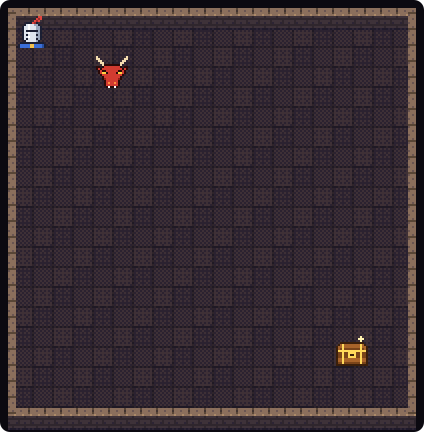

maze as adiacency list:
{(0, 0): [(1, 0), (0, 1)], (0, 1): [(1, 1), (0, 0), (0, 2)], (0, 2): [(1, 2), (0, 1), (0, 3)], (0, 3): [(1, 3), (0, 2), (0, 4)], (0, 4): [(1, 4), (0, 3), (0, 5)], (0, 5): [(1, 5), (0, 4), (0, 6)], (0, 6): [(1, 6), (0, 5), (0, 7)], (0, 7): [(1, 7), (0, 6), (0, 8)], (0, 8): [(1, 8), (0, 7), (0, 9)], (0, 9): [(1, 9), (0, 8)], (1, 0): [(0, 0), (2, 0), (1, 1)], (1, 1): [(0, 1), (2, 1), (1, 0), (1, 2)], (1, 2): [(0, 2), (2, 2), (1, 1), (1, 3)], (1, 3): [(0, 3), (2, 3), (1, 2), (1, 4)], (1, 4): [(0, 4), (2, 4), (1, 3), (1, 5)], (1, 5): [(0, 5), (2, 5), (1, 4), (1, 6)], (1, 6): [(0, 6), (2, 6), (1, 5), (1, 7)], (1, 7): [(0, 7), (2, 7), (1, 6), (1, 8)], (1, 8): [(0, 8), (2, 8), (1, 7), (1, 9)], (1, 9): [(0, 9), (2, 9), (1, 8)], (2, 0): [(1, 0), (3, 0), (2, 1)], (2, 1): [(1, 1), (3, 1), (2, 0), (2, 2)], (2, 2): [(1, 2), (3, 2), (2, 1), (2, 3)], (2, 3): [(1, 3), (3, 3), (2, 2), (2, 4)], (2, 4): [(1, 4), (3, 4), (2, 3), (2, 5)], (2, 5): [(1, 5), (3, 5), (2, 4), (2, 6)], (2,

In [111]:
# The maze from the drawing above: 3 rows, 4 columns, three walls.
## generate a empty maze with default size 10x10
maze = Maze()

## if we want a walled maze, we can use the random_walls() function
## the first argument is the number of the columns,
## density regulates the number of walls: 0 no walls, 1 entirely locked. 

#maze = Maze(10, walls=random_walls(10, density=0.5))


## set up starting positions
knight_position = (0, 0)  
dragon_position = (1, 2)  
goal_position = (8, 8)   

## draw the maze itself, with the knight, dragon, and goal marked.
## print(maze.render(...)) with the same marks draws it as text instead.
display(maze.draw({knight_position: "K", 
                   dragon_position: "D", 
                   goal_position: "G"}))

## now we can also print the entire graph as an adiacency list.
print("maze as adiacency list:")
print(maze.adjacency())

## if we want to access the neighbours of a specific cell, 
## we can use the neighbours() method:
print("neighbours of (0, 0):")
print(maze.neighbours((knight_position)))




### The hidden maze. 

The new level sees the knight struggling in the dark: the knight only sees the cells withing the 'sight' range, and walls block the view. 

In this version of the maze we have a new function and an update to the pre-existing one. 


<code>look_from</code>: find where the knight is in the maze. </br>
<code>maze.visible_from(cell)</code>: returns all the cells visible from the cell </br>
<code>neighbours</code>: works just for the cells in the range of sight of the knight. 

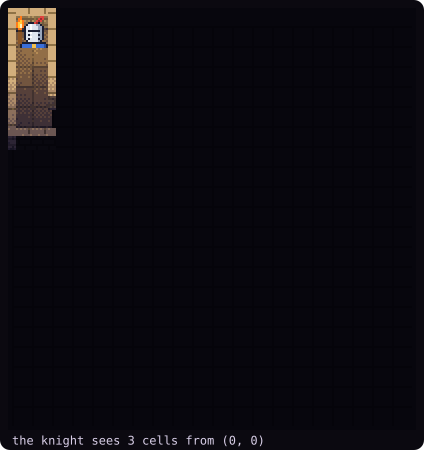

visible cells: [(0, 0), (1, 0), (2, 0)]
neighbours of the knight's cell: [(1, 0)]
Unseen: cannot look at (8, 8): it is not visible from (0, 0)
Unseen: the maze is hidden: there is no adjacency list to copy, look around with neighbours() from where the knight stands


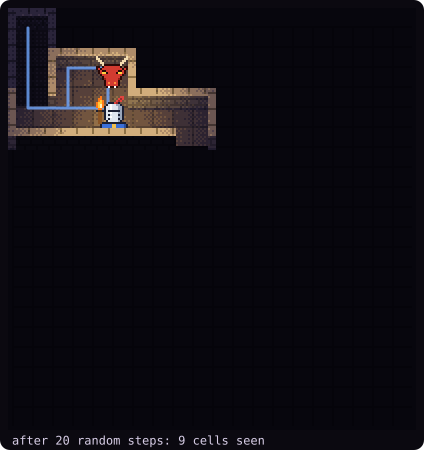

█████████████████████████████████████████
█ ↓ █░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   █████████   ·   ·   ·   ·   ·   ·   █
█ ↓ █ →   D █░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   █   ·   █████████   ·   ·   ·   ·   █
█ →   →   K         █░░░ ░░░ ░░░ ░░░ ░░░█
█████████████████   █   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   ·   ·   ·   ·   ·   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   ·   ·   ·   ·   ·   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   ·   ·   ·   ·   ·   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   ·   ·   ·   ·   ·   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   ·   ·   ·   ·   ·   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█   ·   ·   ·   ·   ·   ·   ·   ·   ·   █
█░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░ ░░░█
█████████████████████████████████████████


In [112]:
## First, generate an hidden maze

knight_position = (0, 0)  
dragon_position = (1, 2)  
goal_position = (8, 8)   

hidden_maze = Maze(10, walls=random_walls(10, 
                                          density=0.8, 
                                          seed=1), 
                        hidden=True, 
                        sight=2)
hidden_maze.look_from(knight_position)
display(hidden_maze.draw({knight_position: "K", 
                          dragon_position: "D", 
                          goal_position: "G"},
                         caption=f"the knight sees {len(hidden_maze.visible)} cells from {knight_position}"))


### in the hidden maze you can call for the visible cells
### or you can call for the neighbours of the knight cell
print("visible cells:", sorted(hidden_maze.visible))
print("neighbours of the knight's cell:", hidden_maze.neighbours(knight_position))

## we can try calling for the ending -- but here is not working naymore. 
for funct_call in (lambda: hidden_maze.neighbours(goal_position), hidden_maze.adjacency):
    try:
        funct_call()
    except Unseen as e:
        print("Unseen:", e)

# The worst knight so far: the random walker: he just randomly strolls 
# The static dragon is not kind to the random knight. 

rng = random.Random(1)
here, steps = knight_position, [knight_position]
for _ in range(20):
    here = rng.choice(hidden_maze.neighbours(here))
    hidden_maze.look_from(here)
    steps.append(here)

display(hidden_maze.draw({here: "K", dragon_position: "D", goal_position: "G"}, knight_path=steps,
                         caption=f"after 20 random steps: {len(hidden_maze.seen)} cells seen"))
print(hidden_maze.render({here: "K", dragon_position: "D", goal_position: "G"}, knight_path=steps))


## OIL IN THE MAZE

The goblins have slipped some oil in the maze. This is a problem only for the knight, since the dragon just... flies over. 

On an oily cell, the knight may slip according to the slip probability (0.4). 

If the knight slips, he ends up one cell on the right or left, or stands still if there is a wall. 

<code>oil="random"</code> pours oil_count puddles of oil_size x oil_size cells, never on the start, the goal or the dragon's cell. </br>

To find if a cell is oily, you can ask <code>maze.is_oil(cell)</code>, which returns a Boolean. 

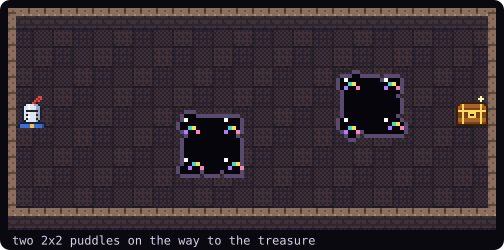

is (2, 4) oily? True   and (0, 0)? False
random puddles on a fresh maze: [(2, 9), (1, 4), (1, 7)]
won: the knight reached the goal in 17 turns; skidded 5 times, on turns [4, 5, 7, 9, 10]


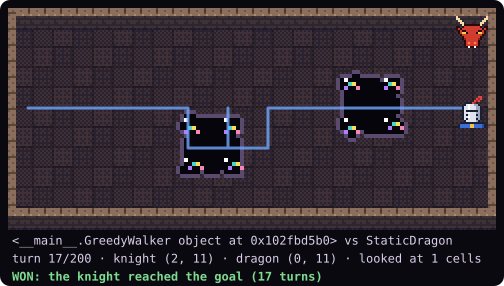

In [113]:
### The oily floor.

## first we manually generate an oily dungeon
hall = Maze(5, 12, oil=[(2, 4), (2, 5), (3, 4), (3, 5), (1, 8), (1, 9), (2, 8), (2, 9)])
display(hall.draw({(2, 0): "K", (2, 11): "G"}, caption="two 2x2 puddles on the way to the treasure"))
print("is (2, 4) oily?", hall.is_oil((2, 4)), "  and (0, 0)?", hall.is_oil((0, 0)))
print("random puddles on a fresh maze:", Maze(10).pour_oil(count=3, size=1, seed=1, avoid=[(0, 0), (9, 9)]))



class GreedyWalker:
    """A knight blinded by greed, only walking towards the treasure."""
    def reset(self, state):
        pass

    def next_move(self, state):
        return min(state.moves_from(state.knight), key=lambda cell: manhattan(cell, state.goal))


# With slip=0.5 the knight skids on half of its moves off the oil. 
game = Game(hall, 
            GreedyWalker(), 
            StaticDragon(), 
            knight_start=(2, 0), 
            dragon_start=(0, 11), 
            goal=(2, 11),
            slip=0.5, 
            rng=random.Random(3))
result = game.run()
print(f"{result.outcome}: {result.reason} in {result.turns} turns; "
      f"skidded {result.slips} times, on turns {game.slips}")
display(game)  

## the knight ran towards the ending. 

In [114]:
"""The knight's strategy. Subclass KnightStrategy to write your own knight.

The knight's maze works similarly to the example maze. 
The information regarding the maze are in the knight's state. 
    
    state.knight, state.dragon, state.goal --> return tuples (row, col), with the positions.    
    state.maze --> is the same maze object as the one above. 
                   you can use the state.maze.neighbours(cell) to get the neighbours of a cell, 
                   state.maze.is_open(a, b) to check if there is a wall between two cells.
                   state.maze.adjacency() gets the adjacency list.
    state.moves_from(cell)        legal moves from a cell (also the cell itself, since the knight can stay put)
    state.dragon_at(k)            where the dragon will be k turns from now, if it can be foreseen
                                  (the PatrolDragon announces its rounds), else None
    state.maze.is_oil(cell)       whether the cell is oily (free). A move off an oily cell skids
    state.slip                    sideways with this probability (see the rules); standing still is safe
    state.visible                 in a hidden maze: the cells the knight sees this turn, within `sight` steps
                                  of it; None elsewhere (it sees everything). neighbours(), is_open() and
                                  is_oil() answer only for these cells: any other raises Unseen and loses
                                  the game. state.dragon is None while the dragon is out of view, and
                                  state.history is empty: what you want to remember, keep on the knight.
    state.thinking_budget         in the budgeted levels: how many cells you may look at in one call of
                                  reset() or next_move(). Every state.moves_from(cell), state.maze.neighbours(cell)
                                  or state.maze[cell] costs one; one too many raises OutOfThought and loses
                                  the game, unless you catch it and still return a move (so look up your
                                  legal moves before you start searching).

    those are ignorable:
    state.turn, state.max_turns   turns played so far, and the limit
    state.dragon_acts_on(turn)    whether the dragon moves on a given turn
    state.history   

The knight is himself an agent. 
Of the knight, you have to implement the next_move() method. 
Each turn the game calls next_move(state).
next_move returns a tuple (row, col), corresponding to the cell to move to, which must be one of state.moves_from(state.knight).
each turn the knight state is then updated, with the new positions of the knight and the dragon. 


    class CustomKnight(KnightStrategy):
        def reset(self, state):
            ...  # optional: runs once before each game
                 ## if you put in the knight state the adjacency list, 
                 ## or something else, you can use reset across games to restore the knight. 

        def next_move(self, state)-> tuple(int, int):
            ...  # return the cell to move to

Implement there the strategy to move to the treasure, happy hunting! 


"""
from abc import ABC, abstractmethod


class KnightStrategy(ABC):
    def reset(self, state):
        """Called once before each game with the starting state. Override it
        to precompute things, or to clear anything kept from a previous game."""

    @abstractmethod
    def next_move(self, state):
        """Return the cell to move the knight to: one of state.moves_from(state.knight)."""

    def __repr__(self):
        return type(self).__name__


In [115]:
# Here, you can create a custom knight that subclasses KnightStrategy,
# and implements a movement algorithm, able to beat the dragon. 

from collections import deque
import heapq

AI_ASSISTANCE = "none"   # which AI tools you used, and for what

## Try to implement first BFS, then Dijkstra, 
## Then, if you have time, try to beat the harder dragons,
## With new intuitions. 

class CustomKnight(KnightStrategy):

    def next_move(self, state):
        moves = state.moves_from(state.knight)
        return min(moves, key=lambda cell: manhattan(cell, state.goal))


In [116]:
from dataclasses import dataclass
from typing import Literal


@dataclass
class MazeDisplay:
    """Class for configuring the display of a maze level."""
    DELAY: float = 0.2            # seconds between turns when watching a game
    STYLE: Literal["token", "pixel", "line", "dungeon"] = "token"   # how the game is drawn: "token", "pixel", "line" or "dungeon"

@dataclass
class MazeLevel:
    """Class for configuring the setting of a maze level."""
    size: int | tuple[int, int] = 10            # side of a square maze, or (rows, cols), e.g. (8, 12)
    walls: None | Literal['random'] | list[tuple[tuple[int, int], tuple[int, int]]] = None  # None (no walls), "random", or a list of ((r, c), (r, c)) pairs
    density: float = 0.8        # for walls="random": share of walls kept (1 = no loops at all)
    seed: int | None = None          # random seed for walls="random"
    knight_start: tuple[int, int] = None  # (row, col); None: the top-left corner
    dragon_start: tuple[int, int] = None  # (row, col); None: the centre
    goal: tuple[int, int] = None          # (row, col); None: the bottom-right corner
    max_turns: int = 200
    dragon_every: int = 1       # the dragon moves once every this many turns (2 = half speed)
    allow_stay: bool = True     # whether standing still counts as a move
    level_number: int = 0        # the level number
    pass_rate: float = 0.8
    thinking_budget: int | None = None   # lookups the knight may make per reset() and per next_move(); None: unlimited
    oil: None | Literal['random'] | list[tuple[int, int]] = None   # None (a dry floor), "random", or a list of oily cells
    oil_count: int = 4          # for oil="random": how many puddles
    oil_size: int = 1           # for oil="random": a puddle is oil_size x oil_size cells
    slip: float = 0.4           # chance that a move off an oily cell skids sideways (see the rules)
    hidden: bool = False        # True: a hidden maze, the knight only sees `sight` steps around it
    sight: int = 2              # for hidden=True: how far the knight sees


    """Class for congiguring the runner of a maze level. """
    dragon: type[DragonStrategy] = StaticDragon  # StaticDragon, GuardDragon, PatrolDragon, GreedyDragon or ChaserDragon

    def settings(self):
        """The game settings, ready for play() and evaluate()."""
        return {key: getattr(self, key) for key in CONFIG}
    




In [117]:
from typing import List
from dataclasses import dataclass, field

LEVELS: dict[str, type[MazeLevel]] = {
    # Base levels, - first lab
    "0": MazeLevel(),
    "1": MazeLevel(walls='random'),
    "2": MazeLevel(walls='random', dragon=GuardDragon),
    "2.5": MazeLevel(walls='random', dragon=GreedyDragon),
    "3": MazeLevel(walls='random', dragon=ChaserDragon, density=0.5, dragon_every=2),
    # Levels with a thinking budget, lab 2 
    "4": MazeLevel(size=20, walls='random', density=0.5, goal=(10, 19), dragon=StaticDragon, thinking_budget=280, pass_rate=0.95),
    "5": MazeLevel(size=20, walls='random', density=0.3, dragon=StaticDragon, thinking_budget=120, pass_rate=0.95),
    "6": MazeLevel(size=20, walls='random', density=0.5, goal=(10, 19), dragon=PatrolDragon, thinking_budget=280, pass_rate=0.9),
    # Hidden Dungeon: the knight sees only `sight` steps around it (state.visible) and has to build its own map.
    "9": MazeLevel(walls='random', hidden=True, sight=2, dragon=StaticDragon, max_turns=300, pass_rate=0.9),
    "10": MazeLevel(walls='random', hidden=True, sight=2, oil='random', oil_count=10, slip=0.4, dragon=StaticDragon, pass_rate=0.9),
    # The guard hunts within 3 steps of its lair, at half speed; the knight sees 3 steps, and the loops let it go around.
    "11": MazeLevel(walls='random', density=0.5, hidden=True, sight=3, dragon=GuardDragon, dragon_every=2, pass_rate=0.8),
}


In [118]:
@dataclass
class RunnerConfiguration: 
    knight: type[KnightStrategy]      # your knight from the cell above, or GreedyKnight for the baseline
    level_list: List[str] = field(default_factory=lambda: list(LEVELS))
    games: None | int = None  # None: watch one game; a number: play that many games silently and summarise
    delay: float = 0.2            # seconds between turns when watching a game
    style: Literal["token", "pixel", "line", "dungeon"] = "dungeon"   # how the game is drawn: "token", "pixel", "line" or "dungeon"
    show: Literal["lost", "first"] | None = "lost"

    def run(self):

        ## Style is a global variable, so we need to change it outside the cell. 
        ## It could be done better. 
        global STYLE
        STYLE = self.style

        if self.games:
            for name in self.level_list:
                print(f"\n=== Level {name} ===")
                level = LEVELS[name]
                evaluate(self.knight, level.dragon, self.games, **level.settings())
        level = LEVELS[self.level_list[-1]]
        play(self.knight, level.dragon, delay=self.delay, **level.settings())


=== Level 1 ===
CustomKnight vs StaticDragon: won 1 of 50 (2%)
    45  the knight ran out of turns
     4  the knight walked into the dragon
     1  the knight reached the goal
  average turns in a win: 18.0
  cells looked at per search: 1 on average, 1 at most

=== Level 2 ===
CustomKnight vs GuardDragon: won 1 of 50 (2%)
    41  the knight ran out of turns
     8  the dragon caught the knight
     1  the knight reached the goal
  average turns in a win: 18.0
  cells looked at per search: 1 on average, 1 at most


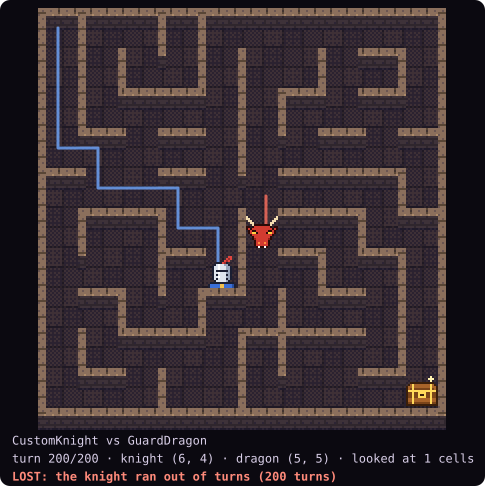

In [119]:
level_results = RunnerConfiguration(
    knight= CustomKnight, 
    games = 50,
    level_list=["1", "2"]
    ).run()
